# Lista 11

## Mathplotlib

(6pkt + 2pkt)

Na liście znajduje się 6 zadań. Po rozwiązaniu zadań, pokaż kod prowadzącemu i odpowiedz na **pytanie kontrolne** — tylko wtedy przyznajemy punkty. Dodatkowo prześlij zadanie na platformie skos.

**Zadania domowe**

Dodatkowe zadania na wyższą ocenę oznaczone są 🏠.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

## Krzywa funkcji straty

Dane są wartości funkcji straty zarejestrowane podczas treningu modelu.

In [2]:
epochs = np.arange(1, 51)
loss = 5.0 * np.exp(-0.12 * epochs) * (1 + 0.02 * np.sin(0.2 * epochs))

**Polecenie**

1. Narysuj wykres funkcji straty (loss) w zależności od epoki (epoch) w skali liniowej.
2. Narysuj ten sam wykres w skali logarytmicznej.
3. Umieść oba wykresy obok siebie.
4. Dodaj tytuły oraz etykiety osi.
5. Wyświetl wykresy.

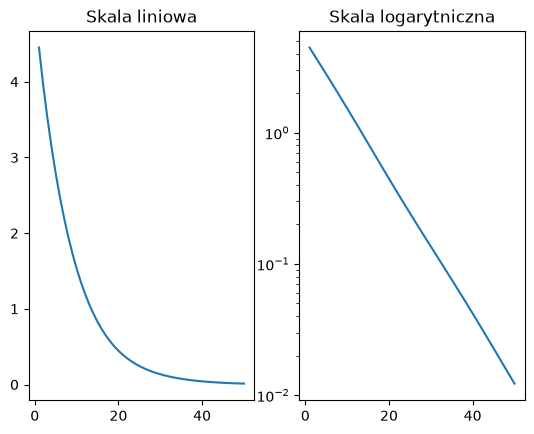

In [3]:
fig, axs = plt.subplot_mosaic([['left', 'right']])

axs['left'].plot(epochs, loss)
axs['left'].set_title('Skala liniowa')

axs['right'].plot(epochs, loss)
axs['right'].set_yscale('log')
axs['right'].set_title('Skala logarytniczna')

plt.show()

## Strata treningowa vs walidacyjna

Podczas treningu zapisywano zarówno stratę treningową, jak i walidacyjną.

In [4]:
epochs = np.arange(1, 11)
train_loss = [5.0, 3.8, 2.9, 2.2, 1.7, 1.3, 1.0, 0.8, 0.7, 0.6]
val_loss   = [5.2, 4.0, 3.1, 2.6, 2.3, 2.1, 2.0, 1.9, 1.9, 1.9]

**Polecenie**

1. Narysuj oba przebiegi na jednym wykresie.
2. Użyj różnych stylów (kolor, linia, marker).
3. Dodaj nazwy osi.
4. Dodaj legendę.
5. Dodaj siatkę (grid).

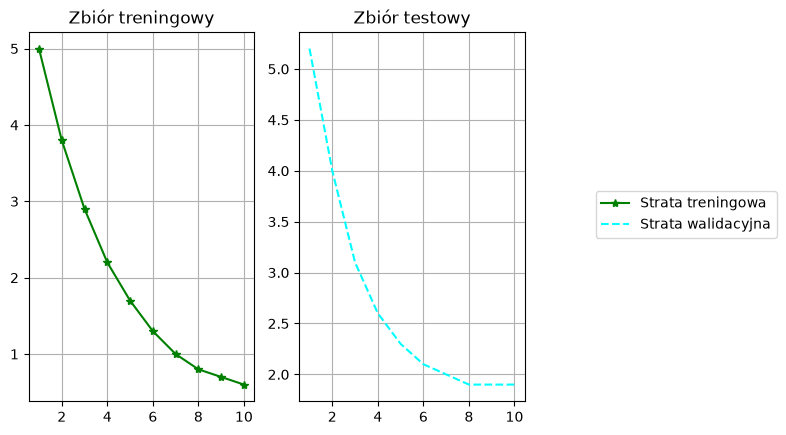

In [5]:
fig2, axs2 = plt.subplot_mosaic([['left', 'right']])
axs2['left'].plot(epochs, train_loss, color="green", marker="*", label="Strata treningowa")
axs2['left'].set_title('Zbiór treningowy')
axs2['left'].grid()

axs2['right'].plot(epochs, val_loss, color="cyan", linestyle="--", label="Strata walidacyjna")
axs2['right'].set_title('Zbiór testowy')
axs2['right'].grid()

fig2.legend(loc="center left", bbox_to_anchor=(1, 0.5))


## Zależność dwóch cech (scatter plot)

W uczeniu maszynowym bardzo często analizuje się **zależności między cechami wejściowymi**.
W tym zadaniu zbadasz relację pomiędzy dwiema cechami za pomocą wykresu punktowego.

Załóżmy, że dane reprezentują:

* dwie cechy wejściowe modelu (np. wzrost i waga, dwie miary z czujnika).

---

**Polecenie**

1. Wygeneruj dane dla dwóch cech, pomiędzy którymi istnieje zależność.
2. Narysuj wykres punktowy (*scatter plot*) pokazujący relację jednej cechy od drugiej.
3. Dodaj etykiety osi oraz tytuł.
4. Włącz siatkę.

In [6]:
np.random.seed(0)
feature_1 = np.random.normal(loc=170, scale=10, size=100)   # e.g. height
feature_2 = 0.5 * feature_1 + np.random.normal(scale=5, size=100)  # correlated feature

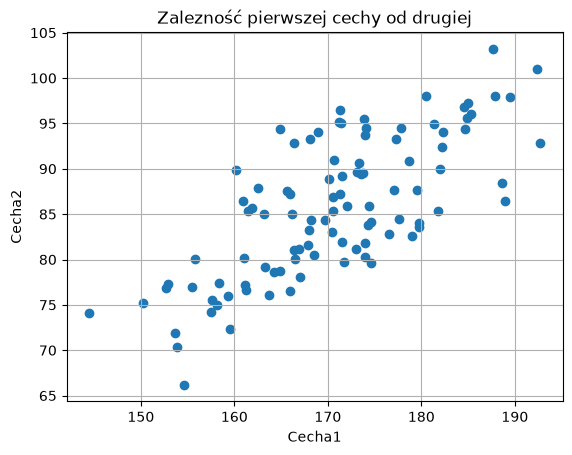

In [7]:
fig3, ax3 = plt.subplots()
ax3.scatter(feature_1, feature_2)
ax3.set_xlabel("Cecha1")
ax3.set_ylabel("Cecha2")
ax3.set_title("Zalezność pierwszej cechy od drugiej")
ax3.grid()

## Rozkład wartości funkcji straty

W uczeniu maszynowym przed trenowaniem modelu bardzo ważne jest zrozumienie rozkładu danych wejściowych.

Załóżmy, że dana cecha reprezentuje np. wiek użytkowników albo wartość pomiaru czujnika.

**Polecenie**

1. Wygeneruj 1000 losowych wartości cechy.
2. Narysuj histogram tych wartości.
3. Zmień liczbę przedziałów (bins) i zaobserwuj różnice.

In [8]:
loss_values = np.random.normal(loc=1.0, scale=0.2, size=1000)

(array([ 1.,  3.,  3.,  1.,  4.,  4.,  9.,  9., 16., 20., 23., 22., 33.,
        43., 47., 47., 57., 68., 65., 74., 57., 72., 59., 39., 44., 40.,
        37., 18., 24., 14., 19.,  4.,  6.,  5.,  6.,  3.,  2.,  1.,  0.,
         1.]),
 array([0.39077139, 0.42185698, 0.45294257, 0.48402816, 0.51511375,
        0.54619933, 0.57728492, 0.60837051, 0.6394561 , 0.67054169,
        0.70162728, 0.73271287, 0.76379846, 0.79488405, 0.82596964,
        0.85705523, 0.88814082, 0.9192264 , 0.95031199, 0.98139758,
        1.01248317, 1.04356876, 1.07465435, 1.10573994, 1.13682553,
        1.16791112, 1.19899671, 1.2300823 , 1.26116788, 1.29225347,
        1.32333906, 1.35442465, 1.38551024, 1.41659583, 1.44768142,
        1.47876701, 1.5098526 , 1.54093819, 1.57202378, 1.60310937,
        1.63419495]),
 <BarContainer object of 40 artists>)

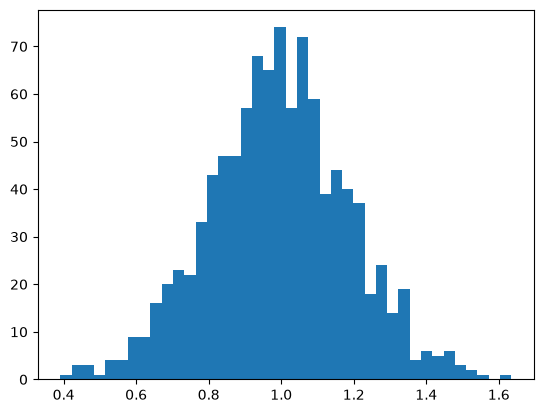

In [9]:
fig4, ax4 = plt.subplots()
ax4.hist(loss_values, bins=40)

## Porównanie rozkładów – histogramy z przezroczystością

W analizie danych i uczeniu maszynowym często porównuje się rozkłady cech dla różnych grup danych
(np. dwie klasy, zbiór treningowy i walidacyjny).

**Polecenie**
1. Wygeneruj dwa zbiory danych reprezentujące dwie różne grupy obserwacji.
2. Narysuj dwa histogramy na tym samym wykresie.
3. Zauważ, że histogramy nachodzą na siebie i są trudne do odczytania.
4. Zmień przezroczystość histogramów, tak aby oba rozkłady były czytelne.
5. Dodaj legendę, tytuł oraz etykiety osi.

In [10]:
np.random.seed(0)

# Generate two distributions
data_1 = np.random.normal(loc=0, scale=1, size=1000)
data_2 = np.random.normal(loc=1, scale=1, size=1000)

Text(0, 0.5, 'Frequency')

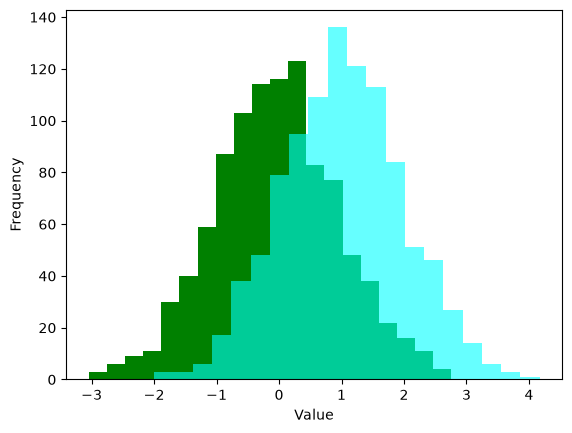

In [11]:
fig4, ax4 = plt.subplots()
ax4.hist(data_1, bins=20, color="green", label="Group1")
ax4.hist(data_2, bins=20, alpha=0.6, color="cyan", label="Group2")

ax4.set_xlabel("Value")
ax4.set_ylabel("Frequency")

## Aspect ratio i geometria na wykresie

Podczas wizualizacji danych kształty i kąty mogą być zniekształcone, jeśli osie mają różne skale.
W tym zadaniu Twoim celem jest zadbać o poprawną geometrię wykresu.

**Polecenie:**

1. Wygeneruj dane opisujące kwadrat w układzie współrzędnych.
2. Narysuj wykres przedstawiający ten kształt.
3. Zauważ, że przy domyślnych ustawieniach osi kwadrat może wyglądać jak prostokąt.
4. Ustaw aspect ratio, tak aby kwadrat zachował poprawny kształt.
5. Dodaj tytuł oraz etykiety osi.

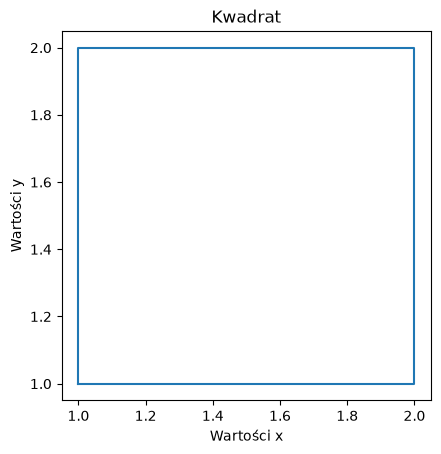

In [12]:
x = [1, 1, 2, 2, 1]
y = [1, 2, 2, 1, 1]

fig5, ax5 = plt.subplots()
ax5.plot(x, y)
ax5.set_xlabel("Wartości x")
ax5.set_ylabel("Wartości y")
ax5.set_title("Kwadrat")

ax5.set_aspect("equal")


## 🏠 Learning curve + feature distribution

Utwórz jedną figurę pokazującą:

1. Przebieg funkcji straty w kolejnych epokach.
2. Rozkład jednej z cech wejściowych modelu.

## 🏠 Plots with custom layout

Utwórz figurę w układzie **2×2**, w której:

* lewa kolumna jest zajęta przez **jeden duży wykres**,
* prawa kolumna zawiera **dwa różne wykresy**.

Postaraj się, zeby Twój wykres był jak najbardziej podobny do ponizszego